In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten, så att Python kan hitta både src/ och data/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar vilken mapp Python arbetar från
print(os.getcwd())

c:\Users\josef\Desktop\data-science-group-project


In [2]:
from src.data_split import load_cleaned_data, get_splits

# Läser in den rensade datan från data/processed/
df = load_cleaned_data()

# Kontrollerar datasetets storlek
print("Antal bokningar:", df.shape[0])
print("Antal kolumner:", df.shape[1])

# Visar fem slumpmässiga bokningar
df.sample(5, random_state=42).T

2026-10-21 19:45:12 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-21 19:45:12 [INFO] src.data_cleaning: Validerar städad data med Pandera...
2026-10-21 19:45:12 [INFO] src.data_cleaning: Datavalidering godkänd utan anmärkningar.
Antal bokningar: 110428
Antal kolumner: 34


,2448,48466,13766,20972,80486
hotel,Resort Hotel,City Hotel,Resort Hotel,Resort Hotel,City Hotel
is_canceled,1,1,0,0,0
lead_time,112,179,73,21,82
arrival_date_year,2016,2016,2015,2016,2016
arrival_date_month,February,July,September,June,May
arrival_date_week_number,7,27,40,23,21
arrival_date_day_of_month,12,1,28,2,17
stays_in_weekend_nights,0,0,1,0,0
stays_in_week_nights,2,2,1,1,3
adults,2,2,2,1,3


In [3]:
# Delar upp den rensade datan kronologiskt
splits = get_splits(df)

# Hämtar träningsdata och valideringsdata
train = splits["train_val"]
val = splits["val"]

# Kontrollerar antal rader och kolumner
print("Train:", train.shape)
print("Validation:", val.shape)

2026-10-21 19:45:22 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-21 19:45:22 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Train: (40414, 34)
Validation: (11643, 34)


### Feature-urval – `deposit_type`

Undersöker hur `deposit_type` påverkar modellens förmåga att förutsäga avbokningar.

Två varianter av Logistic Regression jämförs:
- **Med `deposit_type`**
- **Utan `deposit_type`**

Syftet är att undersöka variabelns betydelse eftersom det är osäkert om informationen alltid finns tillgänglig vid bokningstillfället.

Båda varianterna tränas och utvärderas på samma data för att få jämförbara resultat.

### Logistic Regression – med `deposit_type`

Modellen tränas och utvärderas med `deposit_type` inkluderad bland förklaringsvariablerna.

In [4]:
from src.preprocessing import split_features_target

# Separera features (X) och målvariabel (y).
X_train, y_train = split_features_target(
    train, include_deposit_type=True
)

X_val, y_val = split_features_target(
    val, include_deposit_type=True
)

# Kontrollera dimensionerna.
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (40414, 12)
y_train: (40414,)
X_val: (11643, 12)
y_val: (11643,)


In [5]:
from src.preprocessing import build_preprocessor

# Skapa preprocessorn med deposit_type inkluderad.
preprocessor = build_preprocessor(include_deposit_type=True)

# Anpassa preprocessorn endast på träningsdatan.
X_train_processed = preprocessor.fit_transform(X_train)

# Omvandla valideringsdatan utan att anpassa preprocessorn på nytt.
X_val_processed = preprocessor.transform(X_val)

# Kontrollera dimensionerna efter preprocessing.
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)

Train: (40414, 117)
Validation: (11643, 117)


In [6]:
from src.logistic_regression import train_logistic_regression

# Träna Logistic Regression med deposit_type.
model_with_deposit = train_logistic_regression(
    X_train_processed, y_train
)

print("Logistic Regression med deposit_type är tränad!")

Logistic Regression med deposit_type är tränad!


In [7]:
from src.prediction import predict_probabilities

# Beräkna sannolikheter för modellen med deposit_type.
probabilities_with_deposit = predict_probabilities(
    model_with_deposit,
    X_val_processed
)

# Visa de första 10 sannolikheterna.
print(probabilities_with_deposit[:10])

[0.12753006 0.12917913 0.21766394 0.10900935 0.15693759 0.11288941
 0.11112331 0.29230055 0.16115243 0.10488716]


In [8]:
from src.evaluation import flag_top_share

# Flagga de 20 % av bokningarna med högst avbokningsrisk.
y_pred_with_deposit = flag_top_share(
    probabilities_with_deposit,
    share=0.20
)

# Kontrollera antal bokningar och flaggade.
print("Totalt antal bokningar:", len(y_pred_with_deposit))
print("Antal flaggade:", y_pred_with_deposit.sum())

Totalt antal bokningar: 11643
Antal flaggade: 2329


### Modellutvärdering

Utvärderar Logistic Regression på valideringsdatan med Precision (20%), Recall (20%), F1-score och PR-AUC.

De 20 % av bokningarna med högst förutsagd avbokningsrisk flaggas.

In [9]:
from src.evaluation import evaluate_top_share

# Utvärdera Logistic Regression med deposit_type.
results_with_deposit = evaluate_top_share(
    y_true=y_val,
    scores=probabilities_with_deposit,
    share=0.20
)

# Visa antal bokningar och korrekt flaggade avbokningar.
print("Totalt antal bokningar:", results_with_deposit["antal_bokningar"])
print("Antal flaggade:", results_with_deposit["antal_flaggade"])
print("Korrekt flaggade:", results_with_deposit["korrekt_flaggade"])

# Visa utvärderingsmåtten.
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric.capitalize()}: {results_with_deposit[metric]:.2%}")

print(f"PR-AUC: {results_with_deposit['pr_auc']:.4f}")

Totalt antal bokningar: 11643
Antal flaggade: 2329
Korrekt flaggade: 1451
Precision: 62.30%
Recall: 35.33%
F1_score: 45.09%
PR-AUC: 0.6006


### Logistic Regression – utan `deposit_type`

Modellen tränas och utvärderas utan `deposit_type` för att undersöka hur variabeln påverkar resultatet.

Samma tränings- och valideringsdata samt modellinställningar används för att möjliggöra en rättvis jämförelse.

In [10]:
# Separera features och målvariabel utan deposit_type.
X_train_without_deposit, y_train_without_deposit = split_features_target(
    train, include_deposit_type=False
)

X_val_without_deposit, y_val_without_deposit = split_features_target(
    val, include_deposit_type=False
)

# Kontrollera dimensionerna.
print("X_train:", X_train_without_deposit.shape)
print("y_train:", y_train_without_deposit.shape)
print("X_val:", X_val_without_deposit.shape)
print("y_val:", y_val_without_deposit.shape)

X_train: (40414, 11)
y_train: (40414,)
X_val: (11643, 11)
y_val: (11643,)


In [11]:
# Skapa preprocessor utan deposit_type.
preprocessor_without_deposit = build_preprocessor(
    include_deposit_type=False
)

# Anpassa preprocessorn på träningsdatan.
X_train_processed_without_deposit = preprocessor_without_deposit.fit_transform(
    X_train_without_deposit
)

# Omvandla valideringsdatan med samma preprocessor.
X_val_processed_without_deposit = preprocessor_without_deposit.transform(
    X_val_without_deposit
)

# Kontrollera dimensionerna.
print("Train:", X_train_processed_without_deposit.shape)
print("Validation:", X_val_processed_without_deposit.shape)

Train: (40414, 114)
Validation: (11643, 114)


In [12]:
# Träna Logistic Regression utan deposit_type.
model_without_deposit = train_logistic_regression(
    X_train_processed_without_deposit,
    y_train_without_deposit
)

print("Logistic Regression utan deposit_type är tränad!")

Logistic Regression utan deposit_type är tränad!


In [13]:
# Beräkna sannolikheter för modellen utan deposit_type.
probabilities_without_deposit = predict_probabilities(
    model_without_deposit,
    X_val_processed_without_deposit
)

# Visa de första 10 sannolikheterna.
print(probabilities_without_deposit[:10])

[0.08009782 0.05531566 0.13442717 0.0762246  0.10732506 0.07267206
 0.07861289 0.27921112 0.17307593 0.07164672]


In [14]:
# Flagga de 20 % av bokningarna med högst avbokningsrisk.
y_pred_without_deposit = flag_top_share(
    probabilities_without_deposit,
    share=0.20
)

# Kontrollera antal bokningar och flaggade.
print("Totalt antal bokningar:", len(y_pred_without_deposit))
print("Antal flaggade:", y_pred_without_deposit.sum())

Totalt antal bokningar: 11643
Antal flaggade: 2329


In [15]:
# Utvärdera Logistic Regression utan deposit_type.
results_without_deposit = evaluate_top_share(
    y_true=y_val_without_deposit,
    scores=probabilities_without_deposit,
    share=0.20
)

# Visa antal bokningar och korrekt flaggade avbokningar.
print("Totalt antal bokningar:", results_without_deposit["antal_bokningar"])
print("Antal flaggade:", results_without_deposit["antal_flaggade"])
print("Korrekt flaggade:", results_without_deposit["korrekt_flaggade"])

# Visa utvärderingsmåtten.
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric.capitalize()}: {results_without_deposit[metric]:.2%}")

print(f"PR-AUC: {results_without_deposit['pr_auc']:.4f}")

Totalt antal bokningar: 11643
Antal flaggade: 2329
Korrekt flaggade: 1402
Precision: 60.20%
Recall: 34.14%
F1_score: 43.57%
PR-AUC: 0.5772


### Jämförelse av Logistic Regression

Resultaten jämförs för modeller med och utan `deposit_type` på samma valideringsdata.

In [16]:
import pandas as pd

comparison = pd.DataFrame({
    "Med deposit_type": results_with_deposit,
    "Utan deposit_type": results_without_deposit
})

# Välj ut utvärderingsmåtten.
comparison = comparison.loc[
    ["precision", "recall", "f1_score", "pr_auc"]
]

# Tydligare namn och formatering.
comparison.index = [
    "Precision (20 %)",
    "Recall (20 %)",
    "F1-score",
    "PR-AUC"
]

# Formatera de tre första raderna som procent och PR-AUC som decimaltal.
display(
    comparison.style.format(
        lambda value: f"{value:.2%}"
    ).format(
        "{:.4f}",
        subset=(["PR-AUC"], slice(None))
    )
)

,Med deposit_type,Utan deposit_type
Precision (20 %),62.30%,60.20%
Recall (20 %),35.33%,34.14%
F1-score,45.09%,43.57%
PR-AUC,0.6006,0.5772


### Slutsats

Logistic Regression ger likvärdiga resultat med och utan `deposit_type` när de 20 % mest riskfyllda bokningarna flaggas. Modellen utan variabeln identifierar två fler avbokningar.

Modellen med `deposit_type` har däremot högre PR-AUC, vilket visar att den har bättre sammanvägd precision och recall när olika gränser för flaggning används.

Eftersom det är osäkert om `deposit_type` alltid är känt vid bokningstillfället är modellen utan variabeln ett relevant alternativ.

## Utvärdering av bokningar med och utan registrerade ändringar

För att undersöka hur modellen presterar för olika typer av bokningar
delas valideringsdatan upp i två grupper baserat på `booking_changes`:

- Bokningar utan registrerade ändringar (`booking_changes == 0`)
- Bokningar med registrerade ändringar (`booking_changes > 0`)

De 20 % av bokningarna med högst risk flaggas i hela valideringsdatan.
Därefter beräknas precision och recall separat för respektive grupp.

In [17]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Dela upp valideringsdatan efter registrerade ändringar.
groups = {
    "Utan ändringar": val["booking_changes"] == 0,
    "Med ändringar": val["booking_changes"] > 0
}

# Använd prediktioner från modellen utan deposit_type.
y_true = pd.Series(y_val_without_deposit, index=val.index)
y_pred_series = pd.Series(y_pred_without_deposit, index=val.index)

results_by_group = []

for group_name, mask in groups.items():
    group_true = y_true.loc[mask]
    group_pred = y_pred_series.loc[mask]

    precision = precision_score(
        group_true, group_pred, zero_division=0
    )

    recall = recall_score(
        group_true, group_pred, zero_division=0
    )

    results_by_group.append({
        "Modell": "Logistic Regression utan deposit_type",
        "Grupp": group_name,
        "Antal bokningar": len(group_true),
        "Antal flaggade": int(group_pred.sum()),
        "Precision": precision,
        "Recall": recall
    })

lr_group_results = pd.DataFrame(results_by_group)

display(
    lr_group_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Modell,Grupp,Antal bokningar,Antal flaggade,Precision,Recall
0,Logistic Regression utan deposit_type,Utan ändringar,9790,1887,65.87%,33.50%
1,Logistic Regression utan deposit_type,Med ändringar,1853,442,35.97%,40.05%


### Logistic Regression – Bokningar med och utan registrerade ändringar

Logistic Regression utan `deposit_type` utvärderades genom att flagga de 20 % av bokningarna med högst avbokningsrisk i hela valideringsdatan. Resultaten delades därefter upp efter `booking_changes`.

- **Utan ändringar:** Precision 67,37 % och recall 34,29 %.
- **Med ändringar:** Precision 37,19 % och recall 41,31 %.

Modellen har högre precision för bokningar utan ändringar, medan recall är högre för bokningar med ändringar.

Skillnaderna visar att modellens resultat varierar mellan grupperna, men kan inte fastställa om dataläckage förekommer eftersom de ursprungliga värdena före eventuella ändringar saknas.

### Confusion Matrix – Logistic Regression utan `deposit_type`

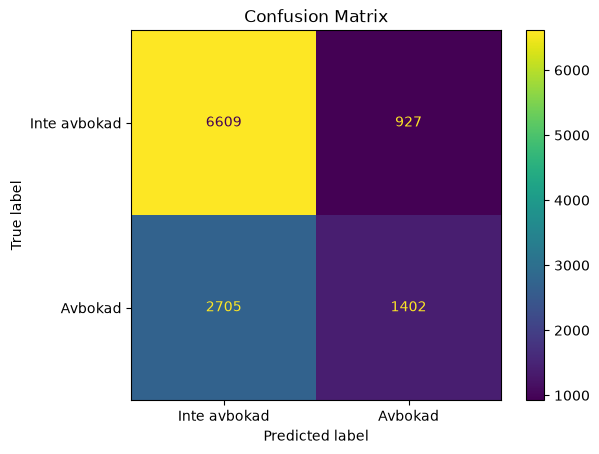

In [18]:
from src.evaluation import plot_confusion_matrix

# Visualiserar modellens förutsägelser mot de faktiska avbokningarna.
# De 20 % av bokningarna med högst avbokningsrisk flaggas.
plot_confusion_matrix(
    y_val_without_deposit,
    y_pred_without_deposit
);

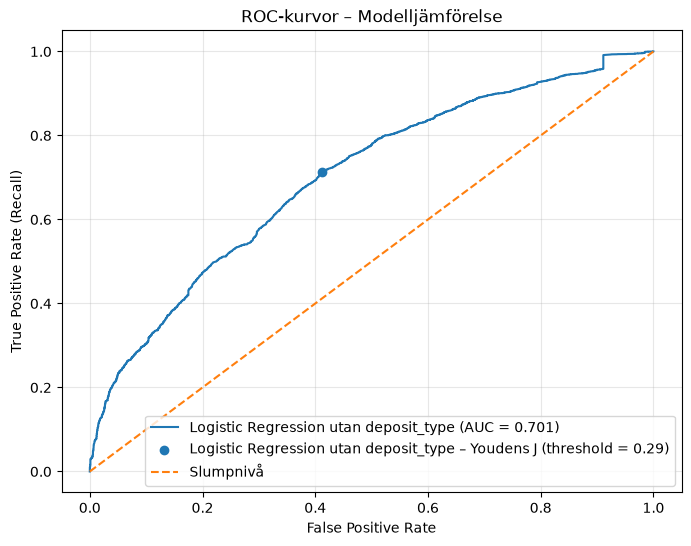

In [19]:
from src.evaluation import plot_roc_curve

# Visa ROC-kurvan för Logistic Regression utan deposit_type.
predictions = {
    "Logistic Regression utan deposit_type": probabilities_without_deposit
}

roc_results = plot_roc_curve(
    y_val_without_deposit,
    predictions
)

In [20]:
# Utvärdera Baseline på samma valideringsdata.
baseline_results = evaluate_top_share(
    y_true=y_val_without_deposit,
    scores=val["lead_time"],
    share=0.20
)

# Jämför Baseline med Logistic Regression utan deposit_type.
for metric in ["precision", "recall", "f1_score"]:
    print(
        f"{metric.capitalize()}: "
        f"Baseline {baseline_results[metric]:.2%} | "
        f"Logistic Regression {results_without_deposit[metric]:.2%}"
    )

print(
    f"PR-AUC: Baseline {baseline_results['pr_auc']:.4f} | "
    f"Logistic Regression {results_without_deposit['pr_auc']:.4f}"
)

Precision: Baseline 54.36% | Logistic Regression 60.20%
Recall: Baseline 30.83% | Logistic Regression 34.14%
F1_score: Baseline 39.34% | Logistic Regression 43.57%
PR-AUC: Baseline 0.5057 | Logistic Regression 0.5772


### Slutsats – Jämförelse med Baseline

Logistic Regression utan `deposit_type` presterar bättre än Baseline på samtliga utvärderingsmått.

Precision (20 %) ökar från 54,36 % till 61,66 % och recall (20 %) från 30,83 % till 34,96 %.

Resultaten visar att Logistic Regression identifierar fler faktiska avbokningar bland de 20 % högst riskbedömda bokningarna.

### Experimentloggning

Resultaten från Logistic Regression med och utan `deposit_type` kan sparas i experimentloggen.

Loggningen är avstängd som standard för att undvika dubbletter när notebooken körs på nytt.

In [ ]:
from src.experiment_logger import log_experiment

# Ändra till True endast när resultaten ska sparas.
SAVE_EXPERIMENTS = False

if SAVE_EXPERIMENTS:
    log_experiment(
        model_name="Logistic Regression",
        feature_set="Med deposit_type",
        metrics=results_with_deposit,
        dataset="val",
        notes="40 414 träningsrader. Tidsbaserad validering. Top 20 %."
    )

    log_experiment(
        model_name="Logistic Regression",
        feature_set="Utan deposit_type",
        metrics=results_without_deposit,
        dataset="val",
        notes="40 414 träningsrader. Tidsbaserad validering. Top 20 %."
    )

    print("Båda experimenten har loggats.")
else:
    print("Experimenten har inte loggats.")

2026-10-21 19:47:37 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv
2026-10-21 19:47:37 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv
Båda experimenten har loggats.
